<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/%C3%B6dev4_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Ortalama Çalışma Süreleri (480x270 Görsel) ---
Prewitt (Gx + Gy) : 3.109 ms
Sobel (Sx + Sy)   : 2.484 ms
7x7 LoG           : 2.769 ms
OpenCV Canny      : 2.316 ms


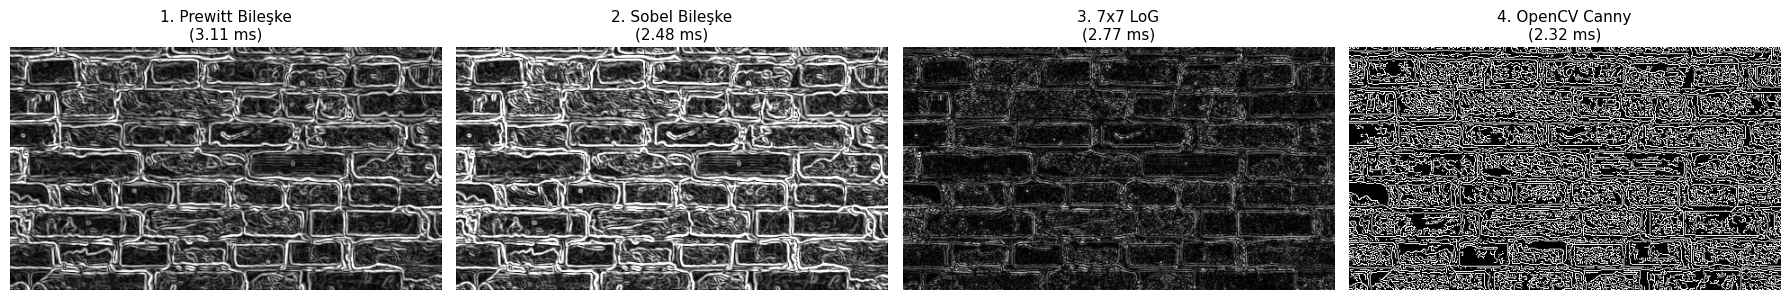

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

# 1. Görseli gri tonlamalı oku
image_path = 'duvar.jpeg'
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    from google.colab import files
    yuklenenler = files.upload()
    image_path = list(yuklenenler.keys())[0]
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Karşılaştırma için tekrar sayısı (süreyi hassas ölçmek için)
NUM_RUNS = 100

# -------------------------------------------------------------
# 1. Prewitt Filtresi ve Süre Ölçümü
# -------------------------------------------------------------
kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
ky = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)

t0 = time.perf_counter()
for _ in range(NUM_RUNS):
    blur_p = cv2.GaussianBlur(image, (3, 3), 1.0)
    px = cv2.filter2D(blur_p, cv2.CV_64F, kx)
    py = cv2.filter2D(blur_p, cv2.CV_64F, ky)
    prewitt_res = np.uint8(np.clip(np.sqrt(px**2 + py**2), 0, 255))
prewitt_time = (time.perf_counter() - t0) / NUM_RUNS * 1000

# -------------------------------------------------------------
# 2. Sobel Filtresi ve Süre Ölçümü
# -------------------------------------------------------------
t0 = time.perf_counter()
for _ in range(NUM_RUNS):
    blur_s = cv2.GaussianBlur(image, (3, 3), 1.0)
    sx = cv2.Sobel(blur_s, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(blur_s, cv2.CV_64F, 0, 1, ksize=3)
    sobel_res = np.uint8(np.clip(np.sqrt(sx**2 + sy**2), 0, 255))
sobel_time = (time.perf_counter() - t0) / NUM_RUNS * 1000

# -------------------------------------------------------------
# 3. 7x7 LoG Filtresi ve Süre Ölçümü
# -------------------------------------------------------------
def get_log_k(size=7, sigma=1.0):
    k = size // 2
    y, x = np.ogrid[-k:k+1, -k:k+1]
    r2 = x**2 + y**2
    kernel = -(1.0 / (np.pi * sigma**4)) * (1.0 - r2 / (2.0 * sigma**2)) * np.exp(-r2 / (2.0 * sigma**2))
    return (kernel - np.mean(kernel)).astype(np.float32)

log_k = get_log_k(7, 1.0)
t0 = time.perf_counter()
for _ in range(NUM_RUNS):
    log_out = cv2.filter2D(image, cv2.CV_64F, log_k)
    log_res = np.uint8(np.clip(np.absolute(log_out), 0, 255))
log_time = (time.perf_counter() - t0) / NUM_RUNS * 1000

# -------------------------------------------------------------
# 4. OpenCV Canny Algoritması ve Süre Ölçümü
# -------------------------------------------------------------
t0 = time.perf_counter()
for _ in range(NUM_RUNS):
    # Eşik değerleri: alt eşik=50, üst eşik=150
    canny_res = cv2.Canny(image, 50, 150)
canny_time = (time.perf_counter() - t0) / NUM_RUNS * 1000

# Süreleri Konsola Yazdır
print(f"--- Ortalama Çalışma Süreleri ({image.shape[1]}x{image.shape[0]} Görsel) ---")
print(f"Prewitt (Gx + Gy) : {prewitt_time:.3f} ms")
print(f"Sobel (Sx + Sy)   : {sobel_time:.3f} ms")
print(f"7x7 LoG           : {log_time:.3f} ms")
print(f"OpenCV Canny      : {canny_time:.3f} ms")

# -------------------------------------------------------------
# Görselleştirme
# -------------------------------------------------------------
plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.title(f"1. Prewitt Bileşke\n({prewitt_time:.2f} ms)", fontsize=11)
plt.imshow(prewitt_res, cmap='gray')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.title(f"2. Sobel Bileşke\n({sobel_time:.2f} ms)", fontsize=11)
plt.imshow(sobel_res, cmap='gray')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.title(f"3. 7x7 LoG\n({log_time:.2f} ms)", fontsize=11)
plt.imshow(log_res, cmap='gray')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.title(f"4. OpenCV Canny\n({canny_time:.2f} ms)", fontsize=11)
plt.imshow(canny_res, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()